In [54]:
%pip install clean-text

In [55]:
%pip install evaluate

In [56]:
import pandas as pd
from cleantext import clean
import re
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import datasets
from transformers import XLNetTokenizer, XLNetForSequenceClassification, TrainingArguments, Trainer, pipeline
import evaluate
import numpy as np
import random


In [130]:
data_test = pd.read_csv("https://raw.githubusercontent.com/wanderer878/jupyter/refs/heads/main/116%20-%20book-reviews-sample.csv")
data_train = pd.read_csv("https://raw.githubusercontent.com/wanderer878/jupyter/refs/heads/main/106%20-%20tripadvisor-hotel-reviews.csv")
data_train.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


<Axes: xlabel='count', ylabel='Rating'>

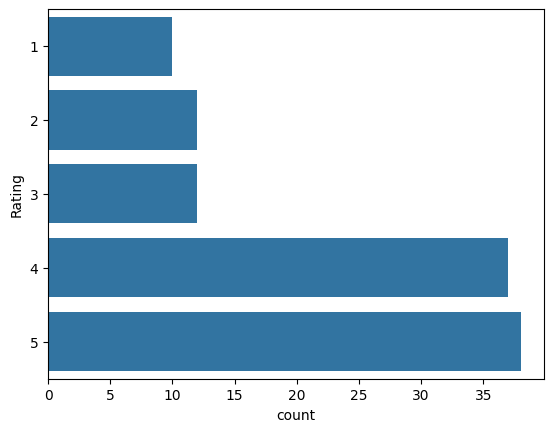

In [131]:
sns.countplot(data_train, y= data_train["Rating"], orient= "h")

In [132]:
g = data_train.groupby('Rating')
g.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5
5,love monaco staff husband stayed hotel crazy w...,5
6,"cozy stay rainy city, husband spent 7 nights m...",5
7,"excellent staff, housekeeping quality hotel ch...",4
8,"hotel stayed hotel monaco cruise, rooms genero...",5
10,"poor value stayed monaco seattle july, nice ho...",2


In [133]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  109 non-null    object
 1   Rating  109 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ KB


In [134]:
# Determine the size of the smallest group
min_size = data_test['rating'].value_counts().min()

# Sample equally from each group directly using groupby.sample
data_test = data_test.groupby('rating').sample(n=min_size, random_state=42).reset_index(drop=True)

# Let's verify the balanced counts and view the head
print(data_test['rating'].value_counts())
display(data_test.head())

rating
1    10
2    10
3    10
4    10
5    10
Name: count, dtype: int64


,index,reviewText,rating
0,11488,And good tittle but not much else here. I boug...,1
1,10934,"its not the worse, but it had a childish feel ...",1
2,6238,I did not order or read this book - it is noth...,1
3,3040,"This was not worth the $0.99, it is a short st...",1
4,1463,Good thing that this is a free story. I read i...,1


In [135]:
from numpy.random import RandomState
min_size = data_train["Rating"].value_counts().min()

data_train = data_train.groupby("Rating").sample(n = min_size, random_state = 42).reset_index(drop = True)

data_train.head()

,Review,Rating
0,quaint not rundown son decided celebrate gradu...,1
1,"noise airconditioner-a standard, arranged stay...",1
2,"stay clear, internet reservation friday rang h...",1
3,horrible customer service hotel stay february ...,1
4,worst hotel experience booked nonsmoking room ...,1


<Axes: xlabel='count', ylabel='rating'>

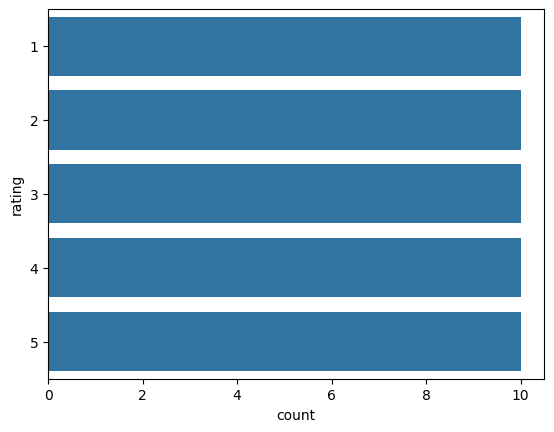

In [136]:
sns.countplot(data_test, y = data_test['rating'], orient = "h")



<Axes: xlabel='count', ylabel='Rating'>

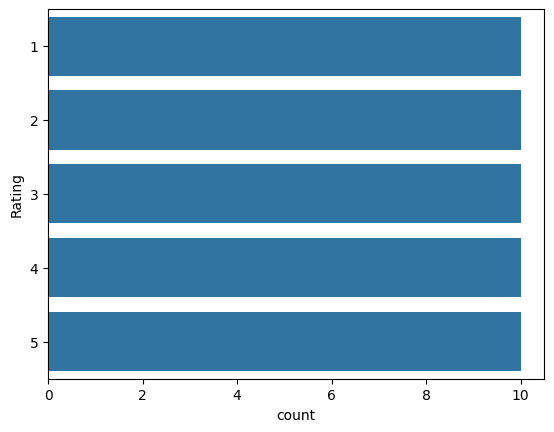

In [137]:
sns.countplot(data_train, y = data_train['Rating'], orient = "h")

In [138]:
Num_rating = 5

In [139]:
train_df = pd.DataFrame({
    "review": data_train.Review.values,
    "label": data_train.Rating.values
})

test_df = pd.DataFrame({
    "review": data_test.reviewText.values,
    "label": data_test.rating.values
})

In [140]:
train_df["label"] = LabelEncoder().fit_transform(train_df["label"])
test_df["label"] = LabelEncoder().fit_transform(test_df["label"])

In [141]:
 train_df = datasets.Dataset.from_dict(train_df)
 test_df = datasets.Dataset.from_dict(test_df)

In [142]:
dataset_dict = datasets.DatasetDict({"train": train_df, "test": test_df})
dataset_dict

DatasetDict({
    train: Dataset({
        features: ['review', 'label'],
        num_rows: 50
    })
    test: Dataset({
        features: ['review', 'label'],
        num_rows: 50
    })
})

In [143]:
tokenizer = XLNetTokenizer.from_pretrained("xlnet-base-cased")

In [144]:
def tokenize_function(row):
  return tokenizer(row["review"], padding= "max_length", max_length=128, truncation= True)

In [145]:
tokenized_dataset = dataset_dict.map(tokenize_function,batched = True)

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

In [146]:
tokenized_dataset

DatasetDict({
    train: Dataset({
        features: ['review', 'label', 'input_ids', 'attention_mask'],
        num_rows: 50
    })
    test: Dataset({
        features: ['review', 'label', 'input_ids', 'attention_mask'],
        num_rows: 50
    })
})

In [147]:
print(tokenized_dataset["train"]["review"][0])

quaint not rundown son decided celebrate graduation high school trip seattle, chose inn queen anne proximity experience music project space needle funky shops eateries nearby, hotel described quaint pictures hotel website nice gave shot.upon entering hotel greeted carpet lobby filthy torn, uh-oh thought not good sign, desk overbooked paid confirmed reservations late arrival 2 weeks prior room left 2 beds, took hurriedly left things room grab quick bite, returning getting bed noticed room no a/c windows not open son double bed clean twin hairy sheets closet, not talking old fashioned wall pull-out bed-this actually tiny twin bed stuffed closet, went kitchenette leftovers fridge fridge mold did not work, went desk complain told nothing sucked tried sleep, took sheets bed used sons blanket eventually closet got stuffy jumped sons bed fan, morning experienced plumbing issues toilet shower bugs bathroom, packing looked bed make sure got discovered possessions stayed did, housekeepers did no

In [148]:
print(tokenized_dataset["train"]["input_ids"][0])

[28657, 50, 446, 2977, 966, 969, 5408, 10202, 227, 297, 1617, 1876, 5979, 19, 4113, 25, 180, 7490, 17, 11483, 14159, 656, 571, 686, 888, 14189, 1572, 3531, 5250, 2514, 13689, 2231, 19, 1645, 1228, 28657, 3027, 1645, 1001, 2101, 675, 938, 9, 14127, 4511, 1645, 12121, 7998, 9496, 29138, 10785, 19, 17, 3314, 13, 4470, 449, 50, 195, 1236, 19, 4318, 95, 3549, 68, 1373, 2207, 12132, 471, 4004, 159, 754, 2114, 520, 263, 159, 10299, 19, 288, 15959, 111, 263, 406, 520, 7417, 2049, 7492, 19, 3416, 723, 1854, 4071, 520, 116, 24, 167, 369, 3367, 50, 433, 966, 1620, 1854, 2146, 5919, 1162, 117, 9243, 12684, 19, 50, 1792, 532, 17, 14050, 1759, 2715, 13, 1281, 1854, 13, 7567, 995, 3703, 5919, 1854, 4, 3]


In [149]:
print(tokenized_dataset["train"]["attention_mask"][0])

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [150]:
model = XLNetForSequenceClassification.from_pretrained(
    "xlnet-base-cased",
    num_labels = Num_rating,
    id2label={0: "1", 1: "2", 2: "3", 3: '4', 4: "5"}
)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
logits_proj.weight              | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [151]:
metric = evaluate.load("accuracy")

In [152]:
def compute_metrices(eval_pred):
  logits, labels = eval_pred
  predictions = np.argmax(logits, axis = -1)
  return metric.compute(predictions= predictions, references= labels)

In [153]:
training_args= TrainingArguments(
    output_dir= "test_trainer",
    eval_strategy= "epoch",
    num_train_epochs= 3
)

In [154]:
trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = tokenized_dataset["train"],
    eval_dataset = tokenized_dataset["test"],
    compute_metrics = compute_metrices
)

In [155]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,1.651667,0.200000
2,No log,1.640750,0.200000
3,No log,1.624642,0.260000


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=21, training_loss=1.649794442313058, metrics={'train_runtime': 468.0332, 'train_samples_per_second': 0.32, 'train_steps_per_second': 0.045, 'total_flos': 10683276249600.0, 'train_loss': 1.649794442313058, 'epoch': 3.0})

In [156]:
trainer.evaluate()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
No log,1.624642,3,0.260000


{'eval_loss': 1.6246417760849, 'eval_accuracy': 0.26}

In [157]:
model.save_pretrained("my_finetuned_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [158]:
finetuned_model = XLNetForSequenceClassification.from_pretrained("my_finetuned_model",)

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

In [159]:
clf = pipeline("text-classification", finetuned_model, tokenizer= tokenizer)

In [171]:
rand_int = random.randint(0, len(test_df))
print(test_df["review"][rand_int])
print(data_test["reviewText"][rand_int])
print(data_test["rating"][rand_int])

I did not care for this ebook. I did not finish reading this ebook. It went at a slow pace.
I did not care for this ebook. I did not finish reading this ebook. It went at a slow pace.
2


In [173]:
answer = clf(test_df["review"][rand_int], top_k = None)
print(answer)

[{'label': '1', 'score': 0.27593570947647095}, {'label': '3', 'score': 0.20777225494384766}, {'label': '5', 'score': 0.20163984596729279}, {'label': '2', 'score': 0.19445355236530304}, {'label': '4', 'score': 0.12019871920347214}]


In [174]:
answer = clf("its good ", top_k = None)
print(answer)

[{'label': '1', 'score': 0.3592875301837921}, {'label': '3', 'score': 0.18445749580860138}, {'label': '2', 'score': 0.17449644207954407}, {'label': '5', 'score': 0.17005851864814758}, {'label': '4', 'score': 0.11169996857643127}]
